In [110]:
import src.digest_util as dig
import src.dna_util as dna
import src.files_util as files

import pandas as pd
import numpy as np
import seaborn as sns

#### Load fasta files for further use

In [111]:
genomes = {'e.coli': [i for i in files.load_fasta_file('fasta/E.Coli/GCF_000005845.2_ASM584v2_genomic.fna')],
           'yeast': [i for i in files.load_fasta_file('fasta/Yeast/GCF_000146045.2_R64_genomic.fna')],
           'roundworm': [i for i in files.load_fasta_file('fasta/Roundworm/GCF_000002985.6_WBcel235_genomic.fna')]
           }

#### List sequences for each organism

In [112]:
# labels
labels = {}
for key, value in genomes.items():
    labels[key] = [i[0] for i in value]

print(labels) # intentionaly using printing for constency

{'e.coli': ['Escherichia coli str. K-12 substr. MG1655'], 'yeast': ['Saccharomyces cerevisiae (Yeast) chromosome I', 'Saccharomyces cerevisiae (Yeast) chromosome II', 'Saccharomyces cerevisiae (Yeast) chromosome III', 'Saccharomyces cerevisiae (Yeast) chromosome IV', 'Saccharomyces cerevisiae (Yeast) chromosome V', 'Saccharomyces cerevisiae (Yeast) chromosome VI', 'Saccharomyces cerevisiae (Yeast) chromosome VII', 'Saccharomyces cerevisiae (Yeast) chromosome VIII', 'Saccharomyces cerevisiae (Yeast) chromosome IX', 'Saccharomyces cerevisiae (Yeast) chromosome X', 'Saccharomyces cerevisiae (Yeast) chromosome XI', 'Saccharomyces cerevisiae (Yeast) chromosome XII', 'Saccharomyces cerevisiae (Yeast) chromosome XIII', 'Saccharomyces cerevisiae (Yeast) chromosome XIV', 'Saccharomyces cerevisiae (Yeast) chromosome XV', 'Saccharomyces cerevisiae (Yeast) chromosome XVI', 'Saccharomyces cerevisiae (Yeast) mitochondrion, complete genome'], 'roundworm': ['NC_003279.8 Caenorhabditis elegans chromoso

#### Drop mitochondrion genes and mergr chromosomes for sake of analysis

In [113]:
# Drop mitochondrion [last element]

genomes['yeast'].pop(len(genomes['yeast']) - 1)
genomes['roundworm'].pop(len(genomes['roundworm'])-1)

# Merge chromosomes

new = {}
for species, genome in genomes.items():
    name = genome[0][0].split('chromosome')[0]
    sequence = ''
    for chromosome in genome:
        sequence = sequence + chromosome[1]
    new[species]= [[name, sequence]]

genomes = new

In [114]:
# Random base sequence

rand_seq = [['rand_gen_len_30_Mb', dna.random_genome(lenght=30*1000000,
                                            seed=4782)]]

In [115]:
# add random genome to genomes dict
genomes['random'] = rand_seq

# digest all sequences
digest = {}

def dig_with_enzyme(sequences, enzyme):
    tmp = {}
    for species, genome in sequences.items():
        rmaps = []
        for chromosome in genome:
            rmaps.append([chromosome[0], dig.digest_with_enzyme(chromosome[1], enzyme)])
            
        tmp[species] = rmaps

    return tmp

for enzyme, pattern in dig.default_enzymes.items():
    digest[enzyme+'('+pattern+')'] = dig_with_enzyme(genomes, enzyme)

# def print_dict(digest_dict):
#     for enzyme, dig in digest_dict.items():
#         print('enzyme : '+enzyme)
#         for species, genome in dig.items():
#             print('\tspecies : '+species)
#             for rmap in genome:
#                 if isinstance(rmap[1], str):
#                     print('\t\t'+rmap[0]+' :\n'+rmap[1][0:200])
#                 else:
#                     print('\t\t'+rmap[0]+' :\n'+rmap[1])
    
# print_dict(digest)
    

In [116]:
def quant_with_value(genome, quants):
    result = []
    for quant in quants:
        result.append([genome[0], quant, 
                       dig.gen_bin_map_from_digest(genome[1], quantize=quant)])
    return result

def quant_all_with_values(digest_dict, quants):
    result = {}
    for enzyme, dig in digest_dict.items():
        result[enzyme] = {}
        for species, genome in dig.items():
            result[enzyme][species] = []
            for chromosome in genome:
                result[enzyme][species].append(
                    quant_with_value(chromosome, quants))
    return result

quant_values = [100, 200, 350, 500, 750, 1000, 2000, 3000, 4000, 5000, 7500, 10000, 12500]

quanted_maps = quant_all_with_values(digest, quant_values)

In [117]:
def frequency(sequence, val='1'):
    count = 0
    for i in sequence:
        if i == val:
            count = count + 1
    return count/len(sequence)

def count_labels_freq(maps):
    data = []
    for enzyme, dig in maps.items():
        for species, genome in dig.items():
            for chromosome in genome:
                tmp = [chromosome[0][0], enzyme]
                for quanted in chromosome:
                    tmp.append(frequency(quanted[2]))
                data.append(tmp)
    return data


freq_of_maps = count_labels_freq(quanted_maps)

table = pd.DataFrame.from_records(freq_of_maps, columns=['genome', 'enzyme']+quant_values)

table

,genome,enzyme,100,200,350,500,750,1000,2000,3000,4000,5000,7500,10000,12500
0,Escherichia coli str. K-12 substr. MG1655,BspQI(GCTCTTC),0.014456,0.028351,0.048937,0.068828,0.100986,0.131193,0.246015,0.339147,0.424634,0.502691,0.638126,0.741935,0.819892
1,Saccharomyces cerevisiae (Yeast),BspQI(GCTCTTC),0.015798,0.031115,0.053610,0.075426,0.110462,0.144798,0.267230,0.368539,0.460239,0.537474,0.680745,0.775662,0.840580
2,NC_003279.8 Caenorhabditis elegans,BspQI(GCTCTTC),0.014536,0.028612,0.049177,0.069106,0.101102,0.131202,0.241438,0.333972,0.417009,0.485964,0.619746,0.716494,0.790077
3,rand_gen_len_30_Mb,BspQI(GCTCTTC),0.012037,0.023960,0.041451,0.058567,0.086775,0.113767,0.214400,0.304400,0.383067,0.455500,0.600750,0.707333,0.789583
4,Escherichia coli str. K-12 substr. MG1655,BssSI(CACGAG),0.017127,0.034125,0.058890,0.083046,0.122152,0.160060,0.295562,0.408915,0.505599,0.580194,0.728595,0.827957,0.897849
5,Saccharomyces cerevisiae (Yeast),BssSI(CACGAG),0.016667,0.033086,0.057089,0.079982,0.118228,0.153579,0.279821,0.384940,0.476143,0.559834,0.707453,0.816225,0.877847
6,NC_003279.8 Caenorhabditis elegans,BssSI(CACGAG),0.022750,0.044752,0.076389,0.107068,0.155149,0.200373,0.353870,0.475093,0.571662,0.648267,0.785864,0.866673,0.917602
7,rand_gen_len_30_Mb,BssSI(CACGAG),0.048170,0.094180,0.158689,0.219400,0.310775,0.391400,0.630600,0.779700,0.868000,0.921500,0.979000,0.992667,0.997917
8,Escherichia coli str. K-12 substr. MG1655,BbvCI(CCTCAGC),0.005386,0.010772,0.018851,0.026928,0.039910,0.052348,0.102542,0.148579,0.192937,0.228202,0.323102,0.397849,0.470430
9,Saccharomyces cerevisiae (Yeast),BbvCI(CCTCAGC),0.007008,0.013967,0.024297,0.034627,0.051441,0.068091,0.131378,0.188370,0.245195,0.290269,0.400621,0.495861,0.574534


In [118]:
def convert_to_points(dataset):
    result = []
    for row in dataset:
        for index in range(2, len(row)):
            result.append([row[0], row[1], row[index], quant_values[index-2]])
    
    return result

points = convert_to_points(freq_of_maps)

plot = pd.DataFrame.from_records(points, columns=['genome', 'enzyme', 'frequency of 1', 'quant size'])


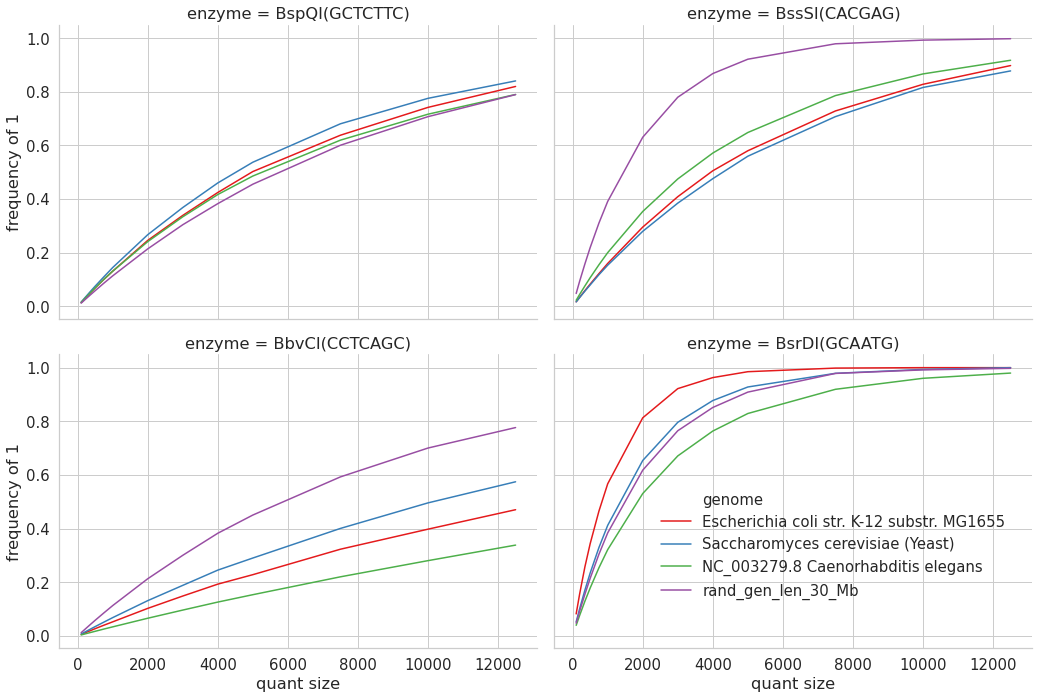

In [119]:
sns.set(font_scale=1.35, style='whitegrid', palette=sns.color_palette("Set1", n_colors=8))
plots = sns.relplot(x="quant size", y="frequency of 1", 
            hue="genome", col="enzyme",
            kind="line", height=5, aspect=1.5, col_wrap=2,
            data=plot, legend='full')

plots._legend.set_bbox_to_anchor([0.58, 0.12])
plots._legend._loc=8

In [120]:
def gen_array_of_dist(maps):
    data = []
    for enzyme, digest in maps.items():
        for species, genome in digest.items():
            for chromosome in genome:
                for quanted in chromosome:
                    dist = dig.gen_distances_from_quants(quanted[2])
                    for d in dist:
                        data.append([quanted[0], enzyme, quanted[1], d])
    return data

distances_arr = gen_array_of_dist(quanted_maps)

distances = pd.DataFrame.from_records(distances_arr, columns=['genome', 'enzyme', 'quant size', 'distance'])

In [159]:
import matplotlib.pyplot as plt

def plot_dist(enzyme, quant):
    data = distances[distances['quant size'] == quant]
    data = data[data['enzyme'] == enzyme]

    data = data.drop(['enzyme', 'quant size'], axis=1)

    g = sns.FacetGrid(data, col='genome', height=5, aspect=1.5, col_wrap=2, legend_out=True)
    g.map(sns.distplot, "distance")
    
    g.fig.subplots_adjust(top=0.9)
    g.fig.suptitle(enzyme+' '+str(quant))

#### Ploting distributions for various quant sizes and all enzymes

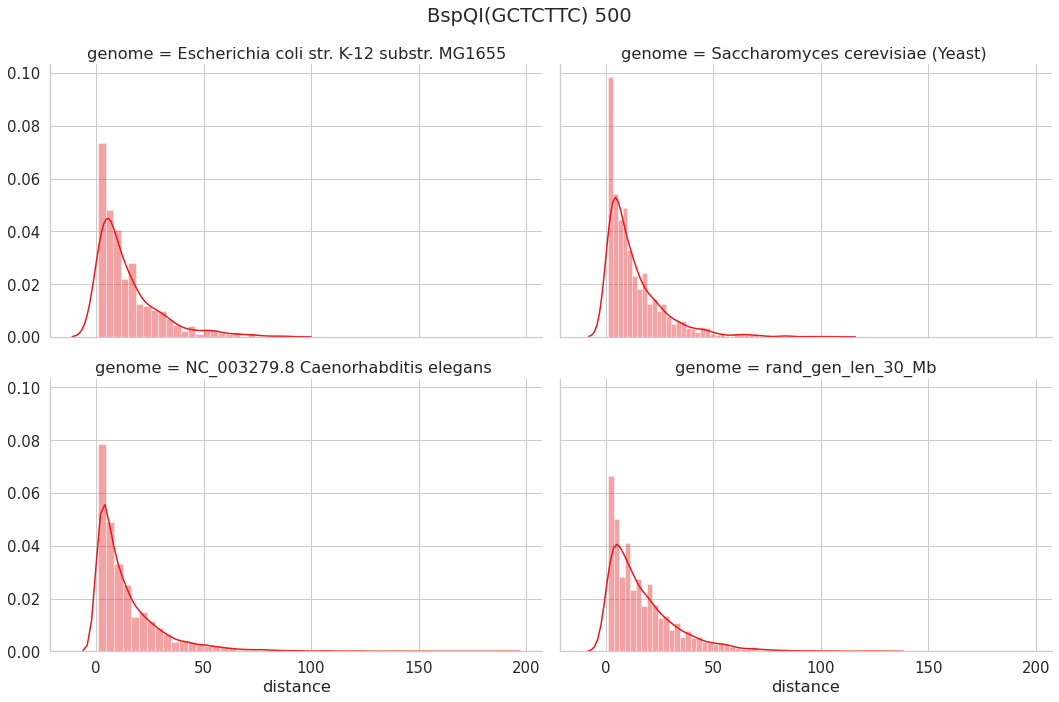

In [160]:
plot_dist('BspQI(GCTCTTC)', 500)

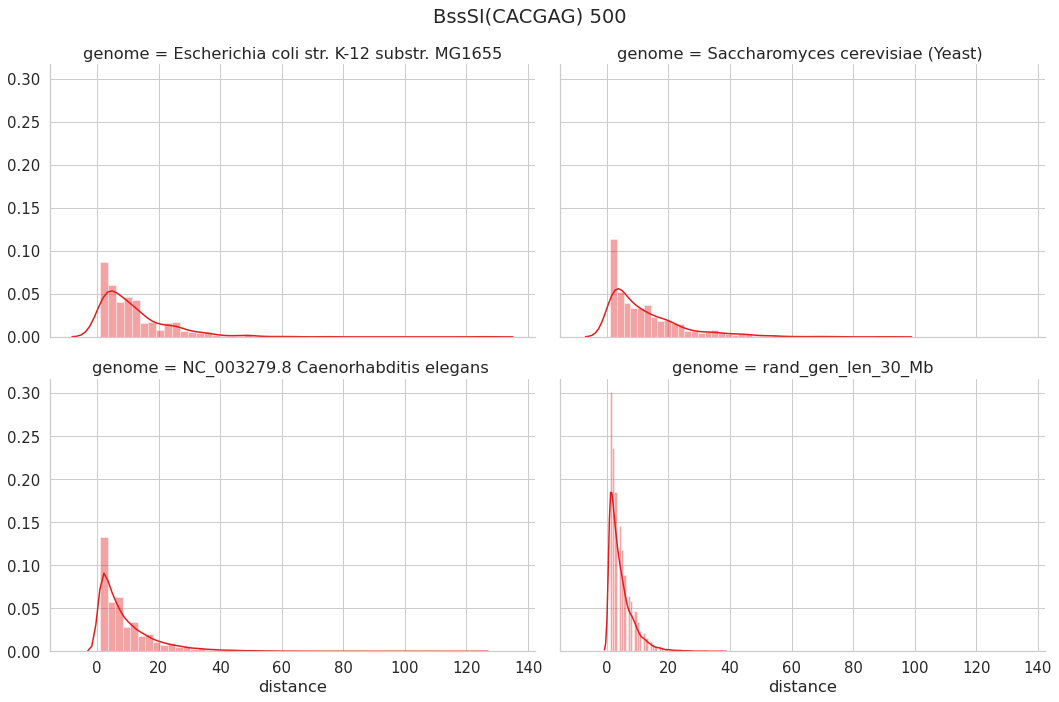

In [161]:
plot_dist('BssSI(CACGAG)', 500)

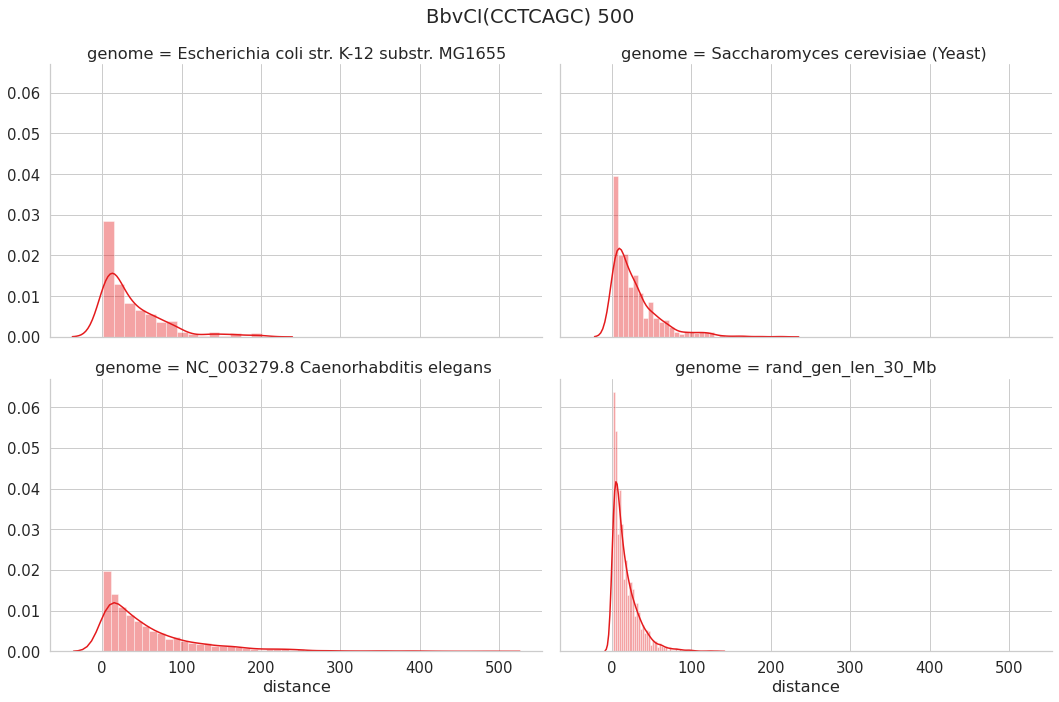

In [162]:
plot_dist('BbvCI(CCTCAGC)', 500)

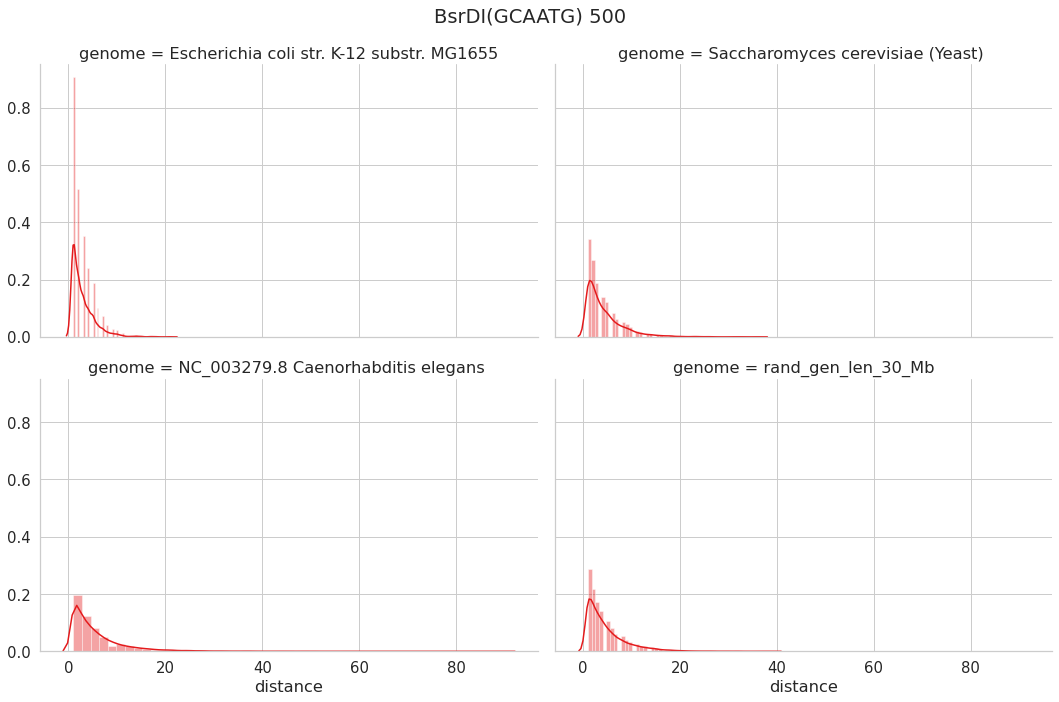

In [163]:
plot_dist('BsrDI(GCAATG)', 500)

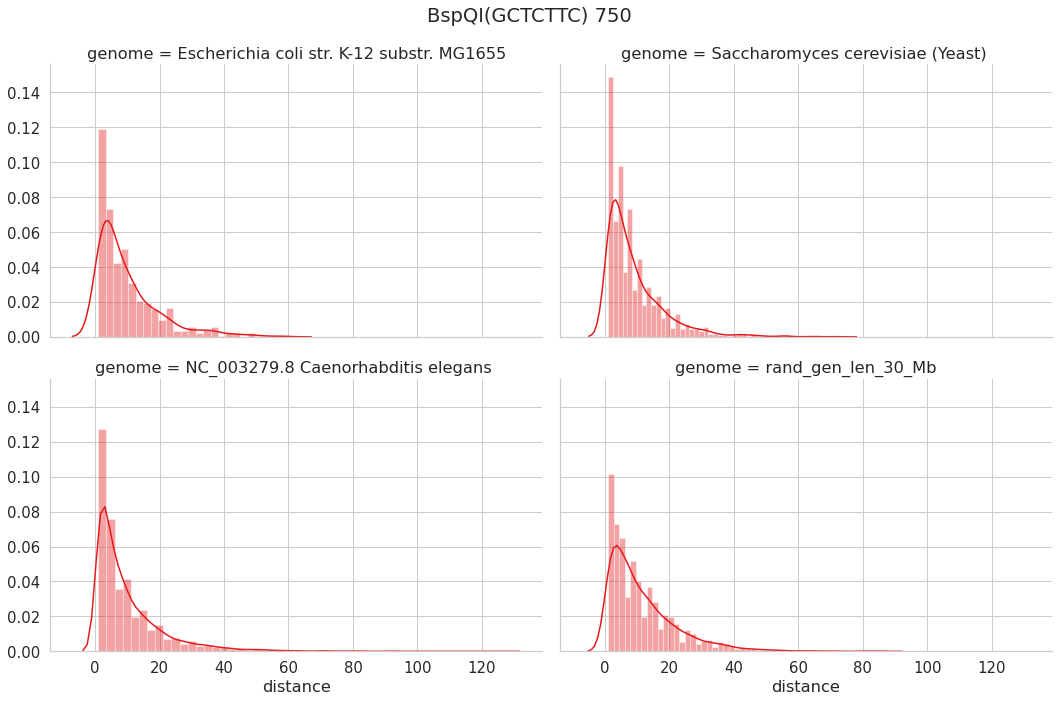

In [164]:
plot_dist('BspQI(GCTCTTC)', 750)

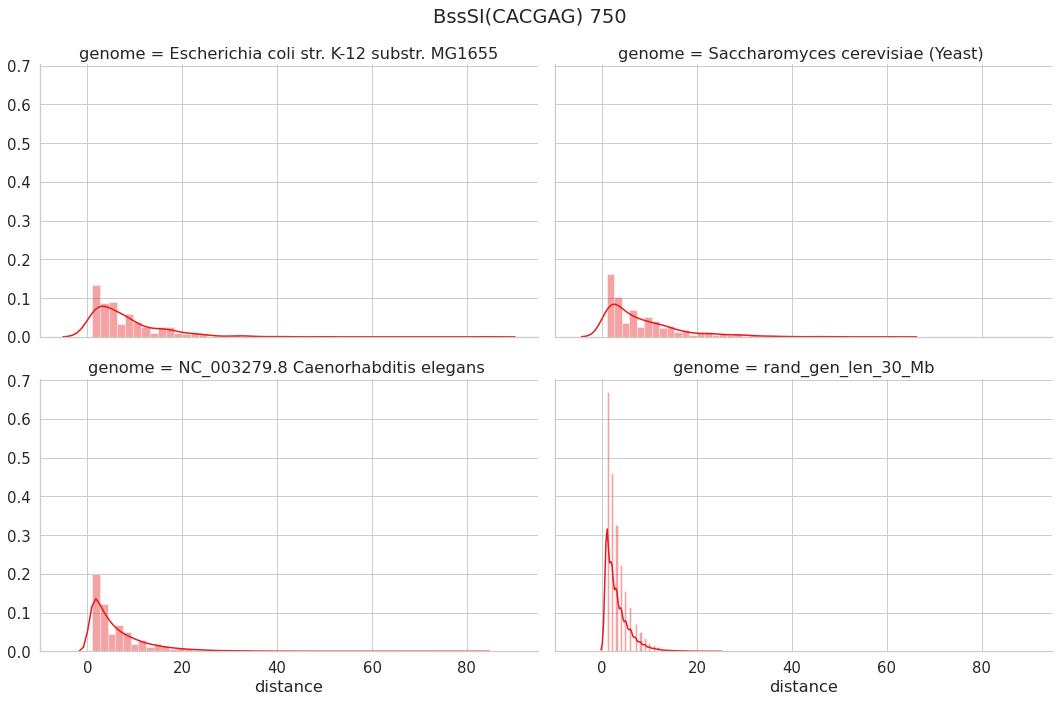

In [165]:
plot_dist('BssSI(CACGAG)', 750)

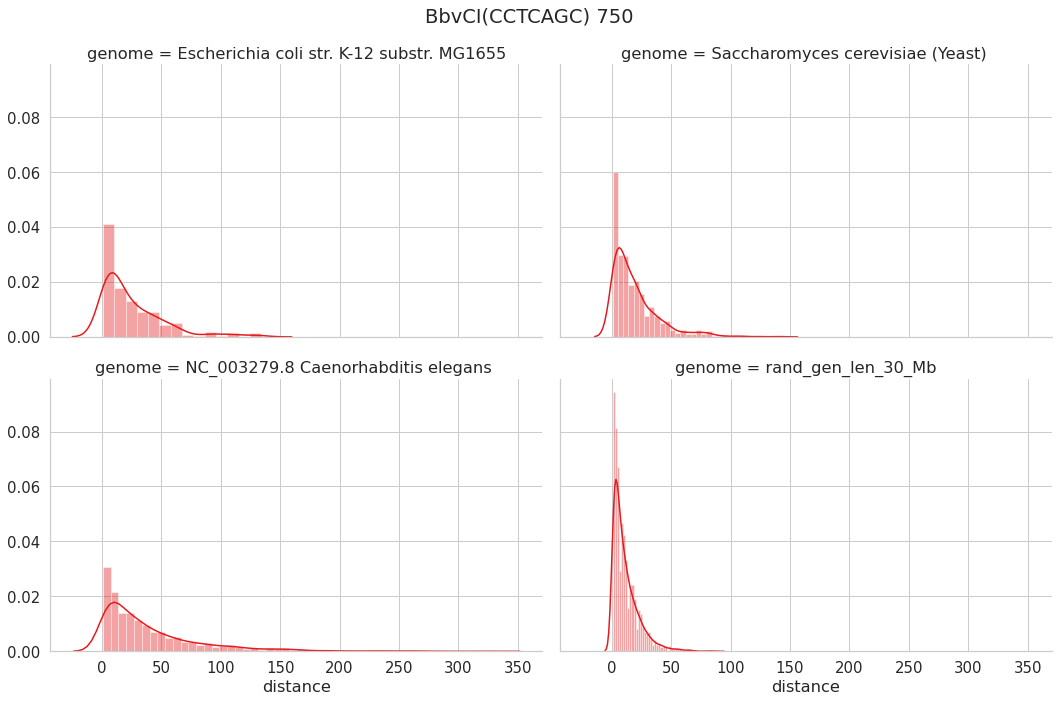

In [166]:
plot_dist('BbvCI(CCTCAGC)', 750)

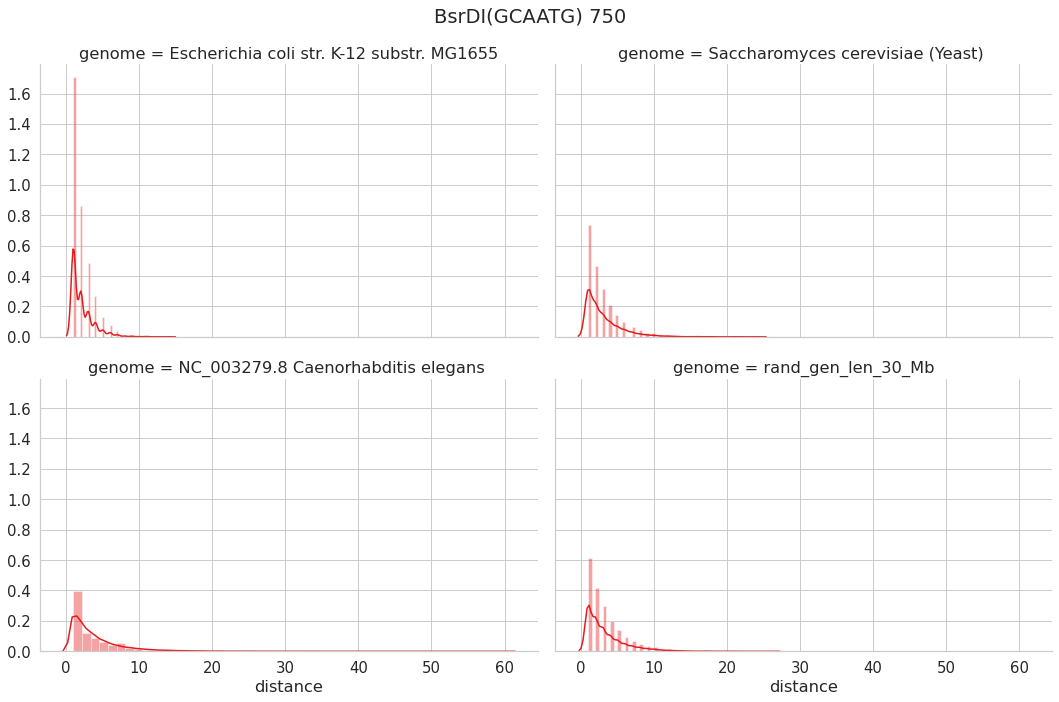

In [167]:
plot_dist('BsrDI(GCAATG)', 750)

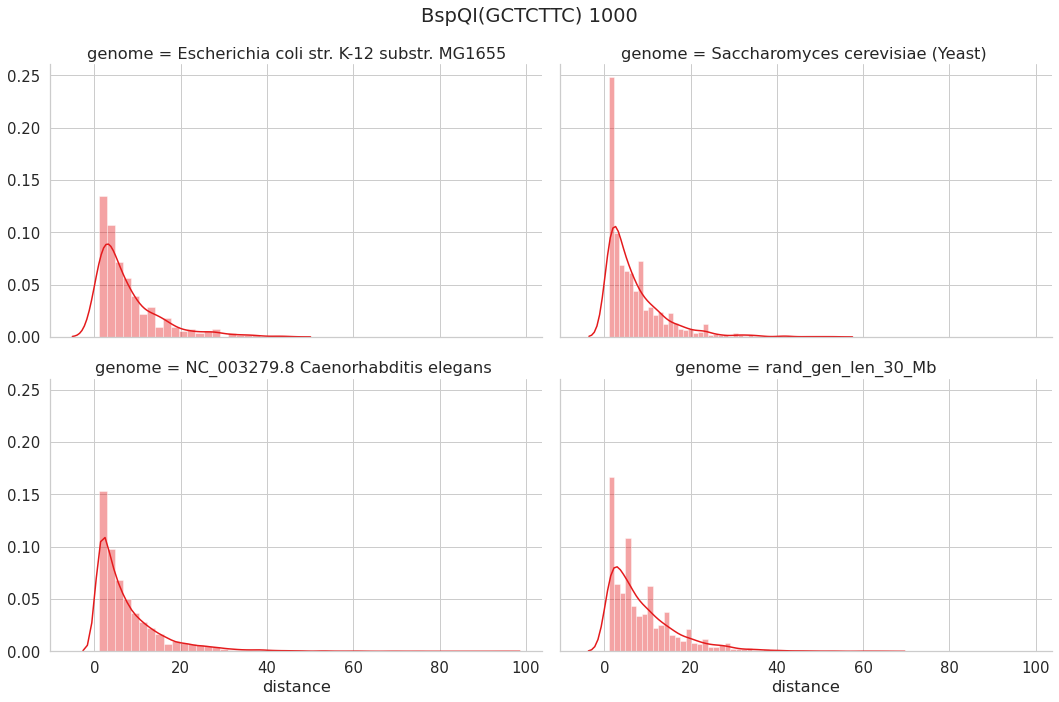

In [168]:
plot_dist('BspQI(GCTCTTC)', 1000)

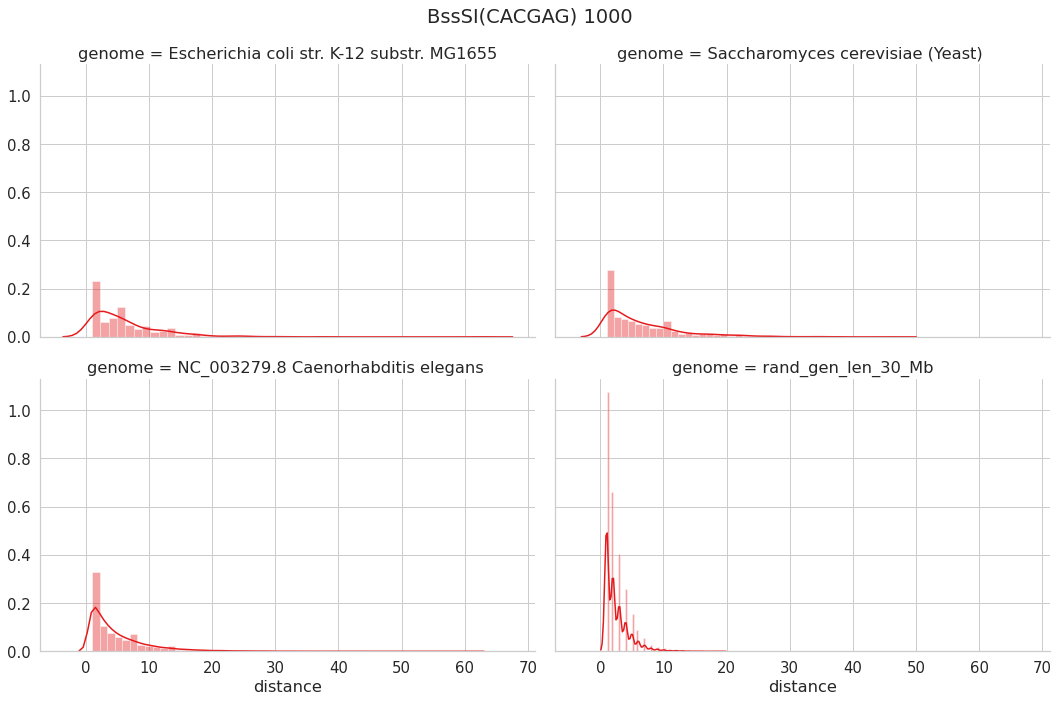

In [169]:
plot_dist('BssSI(CACGAG)', 1000)

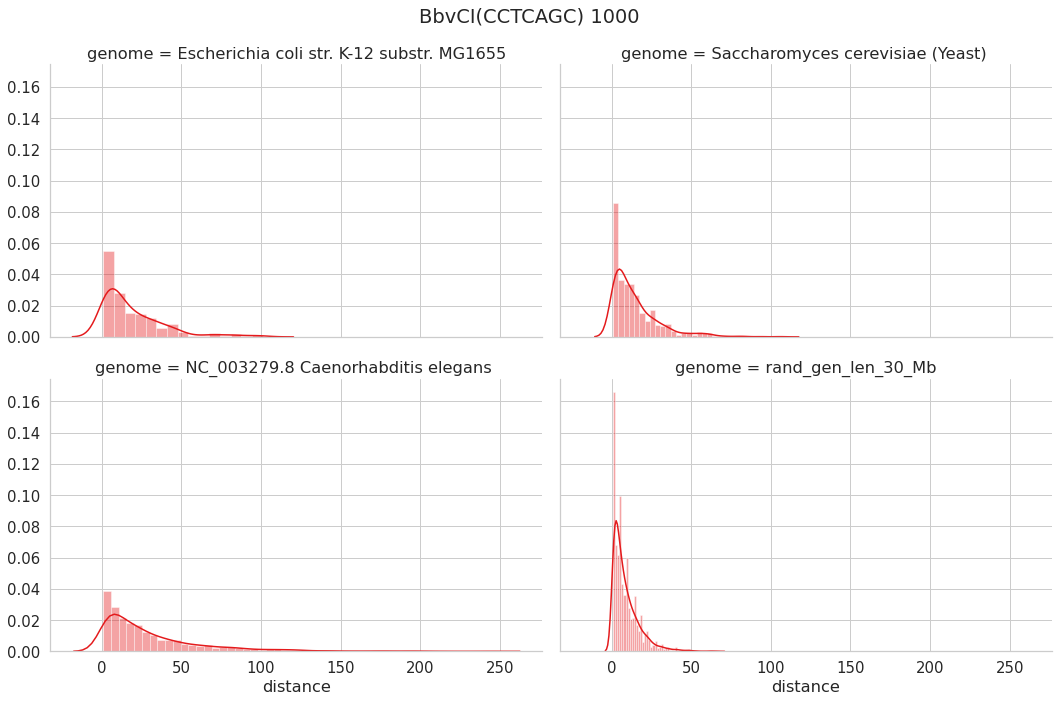

In [170]:
plot_dist('BbvCI(CCTCAGC)', 1000)

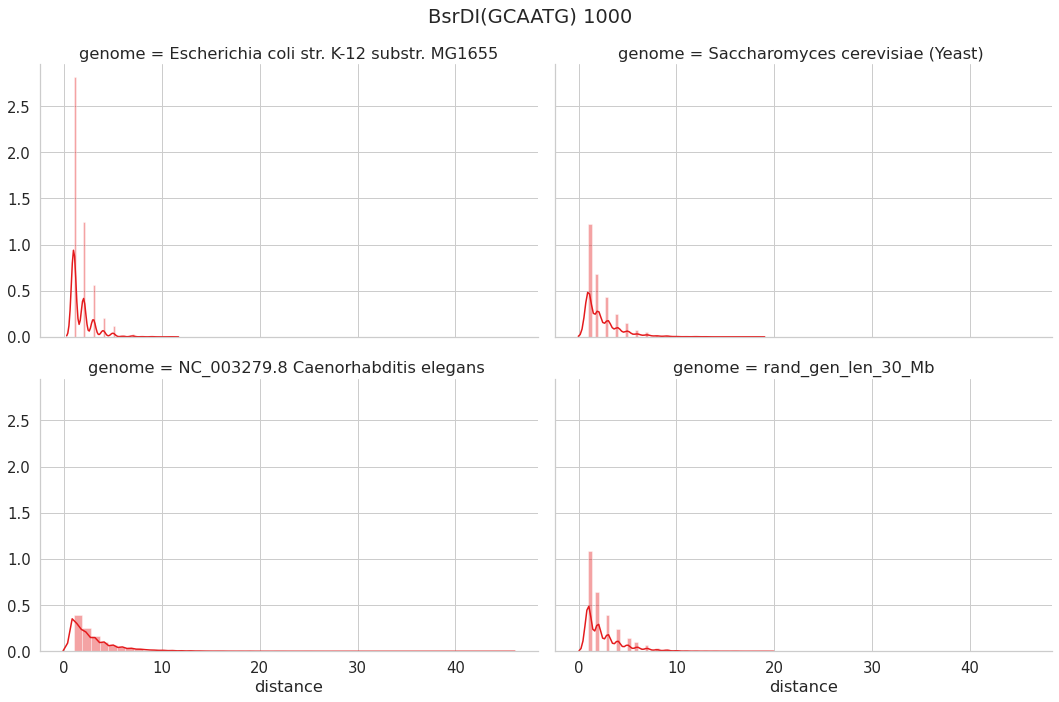

In [171]:
plot_dist('BsrDI(GCAATG)', 1000)

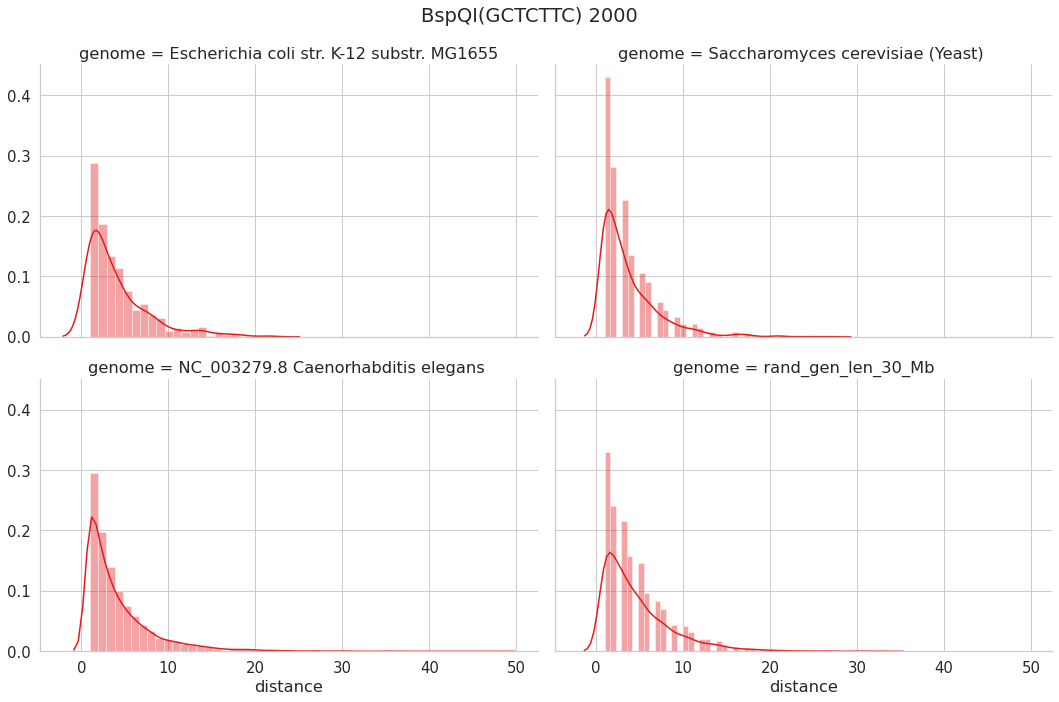

In [172]:
plot_dist('BspQI(GCTCTTC)', 2000)

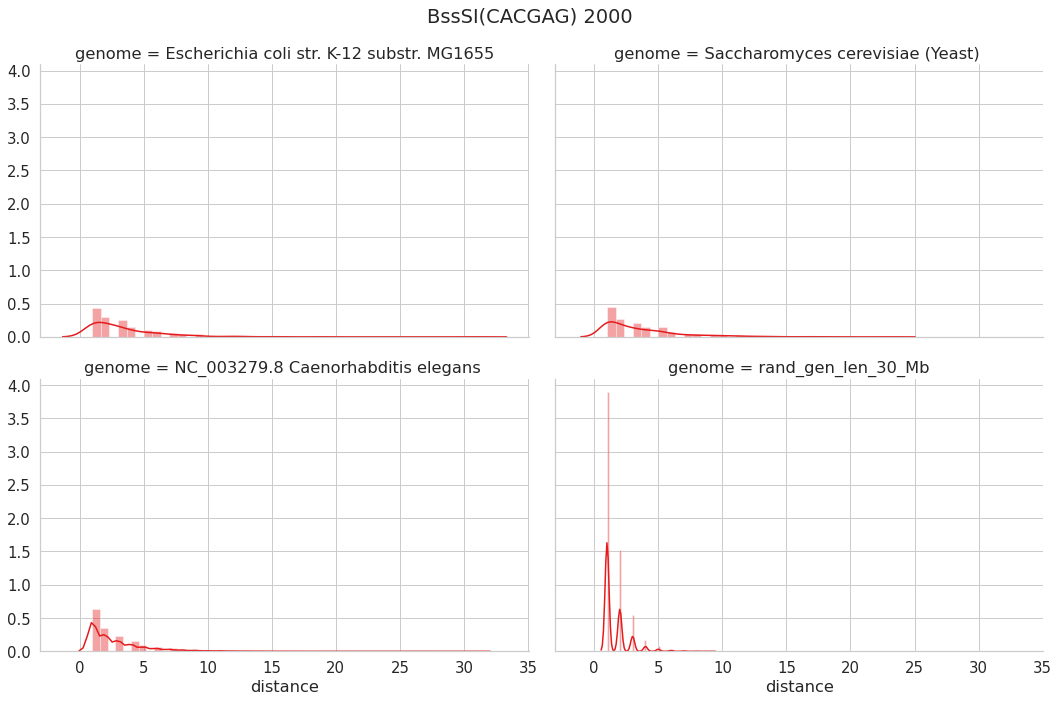

In [173]:
plot_dist('BssSI(CACGAG)', 2000)

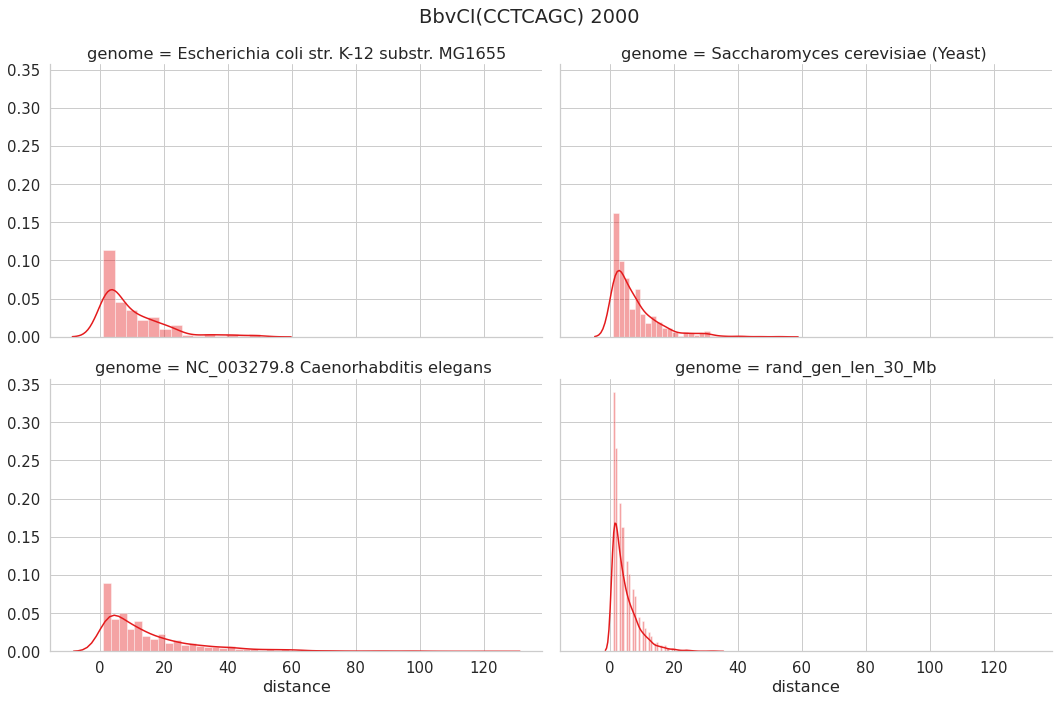

In [174]:
plot_dist('BbvCI(CCTCAGC)', 2000)

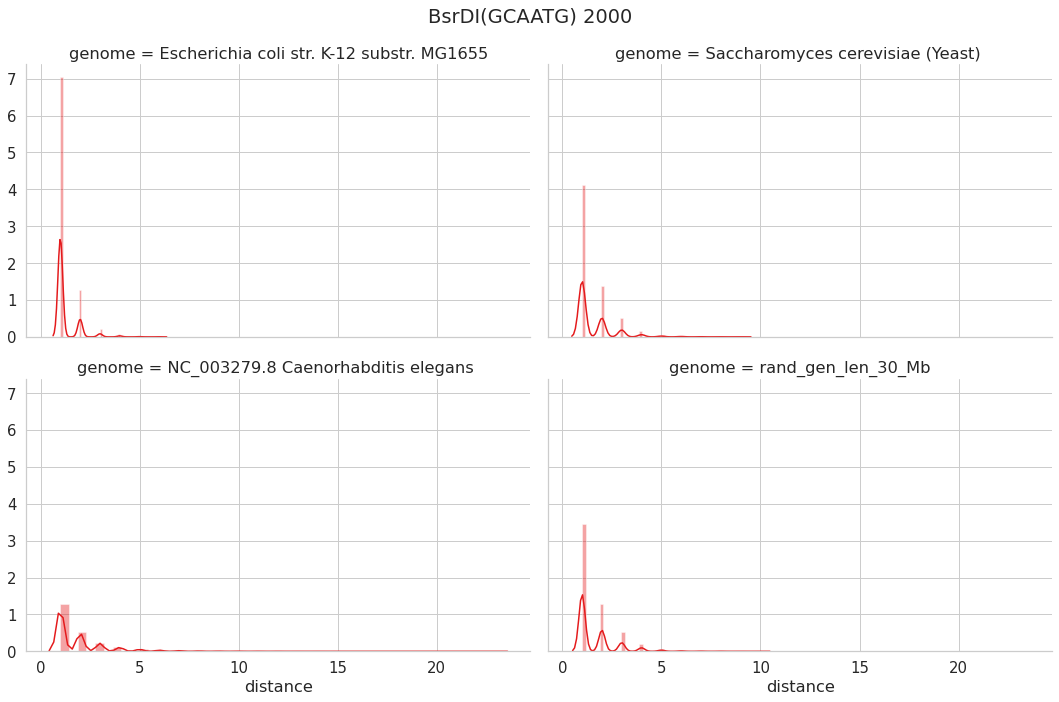

In [175]:
plot_dist('BsrDI(GCAATG)', 2000)